# Phase 11: Comprehensive Failure Analysis & Tiny Stone Error Taxonomy

**Scientific Question:**
*Where, how, and why do global full-field architectures fail on KUB radiographs?*

**Clinical and Methodological Motivation:**
While UNet++ established the strongest global baseline (Macro Dice 0.7625), clinical KUB interpretation demands near-zero false negatives for obstructive calculi. In full-field radiographs ($2000 	imes 2000+$ pixels downscaled to $512 	imes 512$), tiny stones (<5mm) occupy as little as 0.01% of the pixel area. 

This phase taxonomizes failure modes across the 106 FULL_FIELD validation images into four distinct categories:
1. **Global-Empty Predictions:** 7 images where the network produced zero positive pixels despite ground truth stones being present.
2. **Missed Components:** Stone components completely undetected (FN).
3. **Severe False Positives:** Non-stone abdominal structures (bowel gas interfaces, phleboliths, vertebral edges) classified as stones.
4. **Low Dice Decile:** Stone boundaries severely truncated or under-segmented.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os, glob
from IPython.display import display, Image

fail_summary_path = 'reports/tables/phase11_kub_failure_summary.csv' if os.path.exists('reports/tables/phase11_kub_failure_summary.csv') else '../../reports/tables/phase11_kub_failure_summary.csv'
if os.path.exists(fail_summary_path):
    f_df = pd.read_csv(fail_summary_path)
    display(f_df)


,Failure_Type,Count,Rate
0,EMPTY_PREDICTION,8,0.028269
1,LOW_DICE_DECILE,29,0.102473
2,HIGH_HD95_DECILE,28,0.098940
3,HIGH_FP_DECILE,39,0.137809
4,MISSED_TINY_COMPONENT,14,0.049470
5,MISSED_SMALL_COMPONENT,3,0.010601
6,PARTIAL_MULTI_COMPONENT_DETECTION,10,0.035336
7,COMPLETE_MULTI_COMPONENT_MISS,4,0.014134
8,MISSED_TINY_ORIGINAL_COMPONENT,16,0.219178
9,MISSED_SMALL_ORIGINAL_COMPONENT,4,0.137931


## Section A: Aggregate Failure Distributions
Below we examine the distribution of false positive components and missed objects across validation cases.


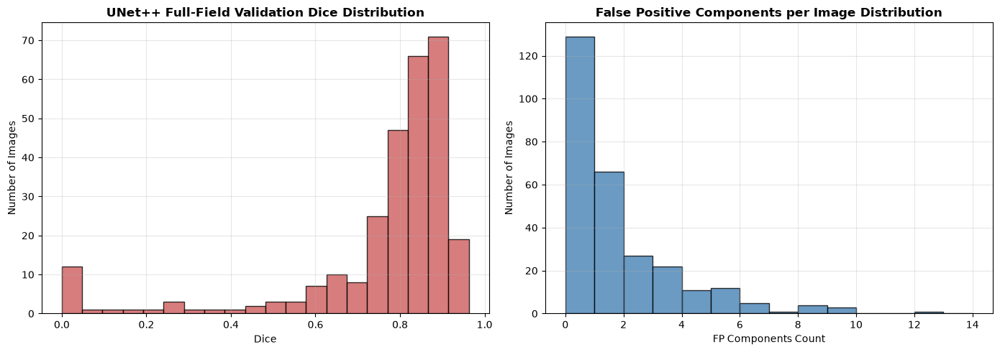

In [2]:
per_img_path = 'reports/tables/phase11_kub_failure_analysis_per_image.csv' if os.path.exists('reports/tables/phase11_kub_failure_analysis_per_image.csv') else '../../reports/tables/phase11_kub_failure_analysis_per_image.csv'
df_img = pd.read_csv(per_img_path)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Dice distribution
axes[0].hist(df_img['dice'], bins=20, color='indianred', edgecolor='black', alpha=0.8)
axes[0].set_title('UNet++ Full-Field Validation Dice Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Dice')
axes[0].set_ylabel('Number of Images')
axes[0].grid(True, alpha=0.3)

# Plot 2: FP component count distribution
axes[1].hist(df_img['fp_eval_components'], bins=range(0, 15), color='steelblue', edgecolor='black', alpha=0.8)
axes[1].set_title('False Positive Components per Image Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('FP Components Count')
axes[1].set_ylabel('Number of Images')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fig_dir = 'reports/figures/retrospective/phase11_failures' if os.path.exists('reports') else '../../reports/figures/retrospective/phase11_failures'
os.makedirs(fig_dir, exist_ok=True)
plt.savefig(os.path.join(fig_dir, 'failure_distributions.png'), dpi=200, bbox_inches='tight')
display(fig)
plt.close(fig)


## Section B: 16 Deterministic Failure Case Studies
Below are 16 deterministic failure cases rendered across the 4 key categories. Each panel displays:
1. **Original Radiograph**
2. **Ground Truth Contour**
3. **Continuous Probability Map**
4. **Binary Prediction Overlay**
5. **Standardized Error Map (Green=TP, Red=FP, Blue=FN)**


Total Detailed Failure Case Studies Loaded: 17


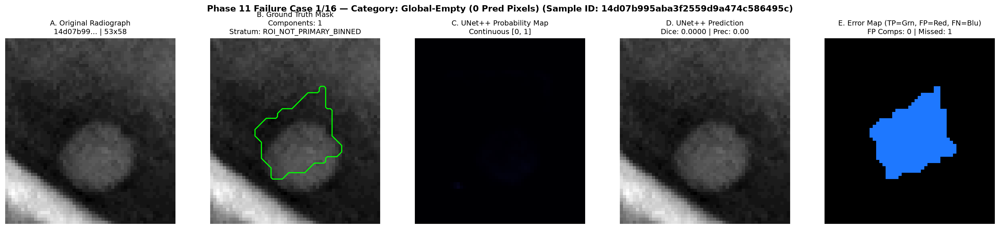

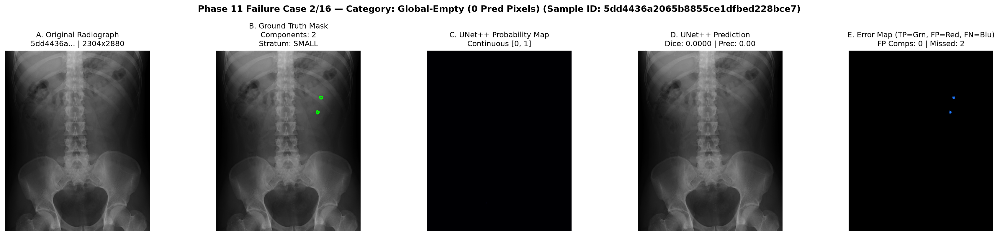

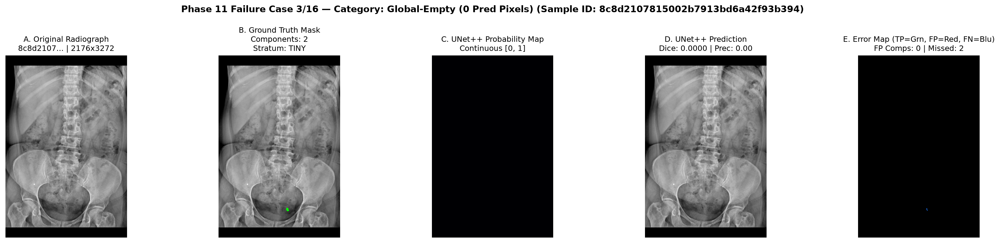

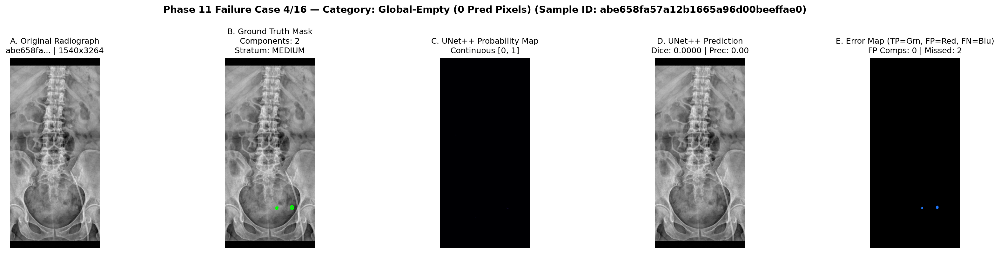

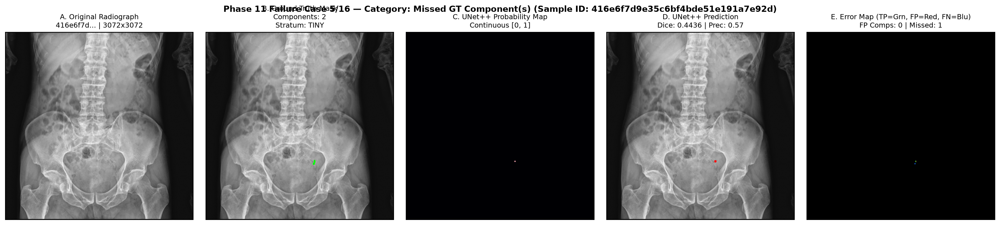

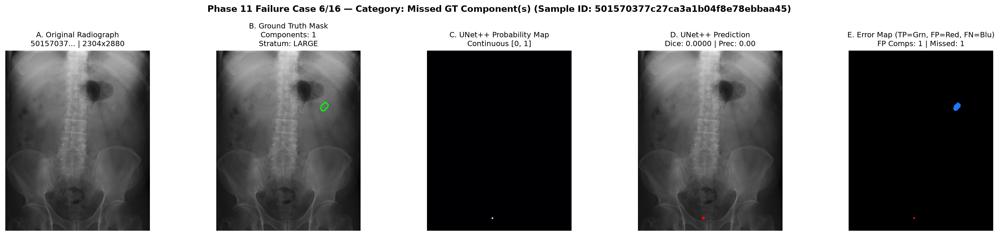

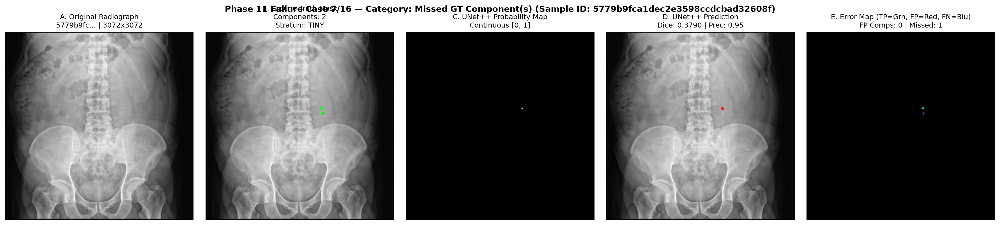

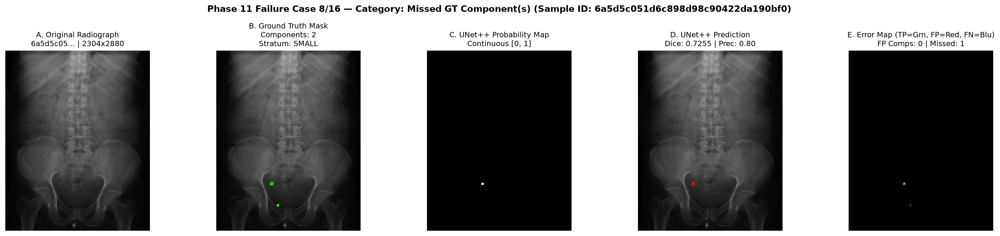

In [3]:
import glob
fig_pattern = 'reports/figures/retrospective/phase11_failures/failure_*.png' if os.path.exists('reports') else '../../reports/figures/retrospective/phase11_failures/failure_*.png'
fail_figs = sorted(glob.glob(fig_pattern))
print(f"Total Detailed Failure Case Studies Loaded: {len(fail_figs)}")

for p in fail_figs[:8]:
    display(Image(filename=p))


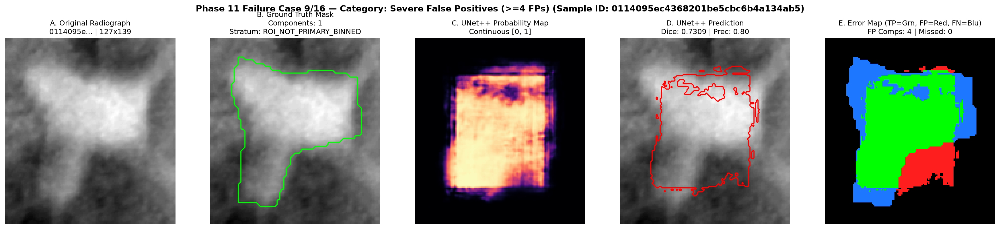

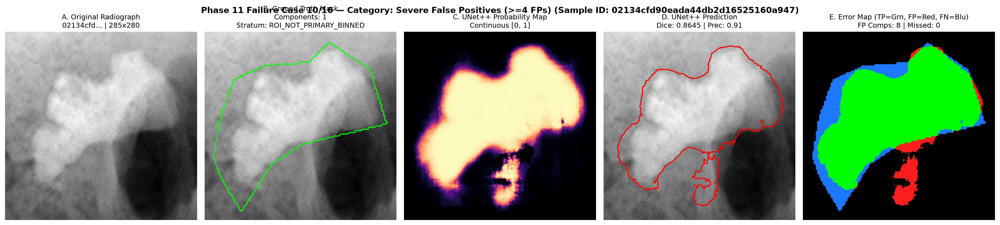

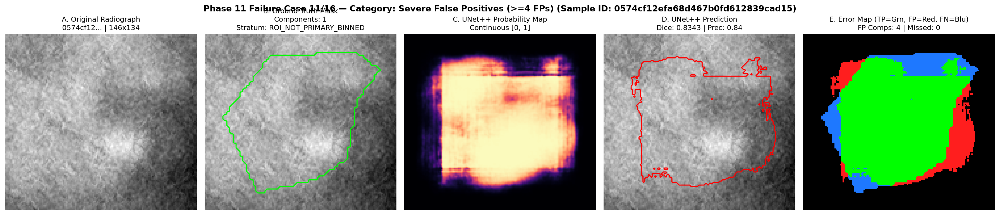

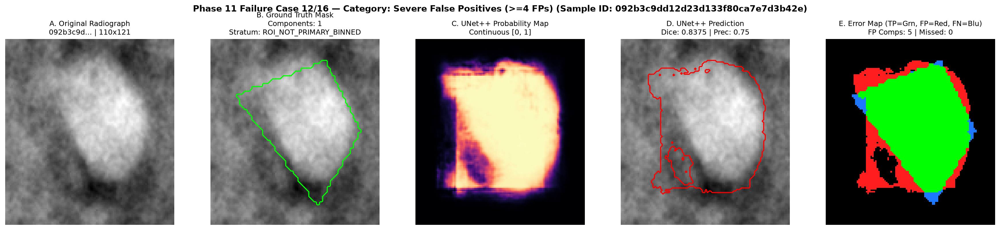

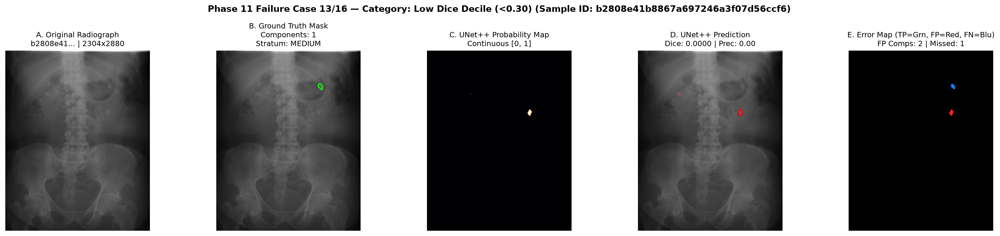

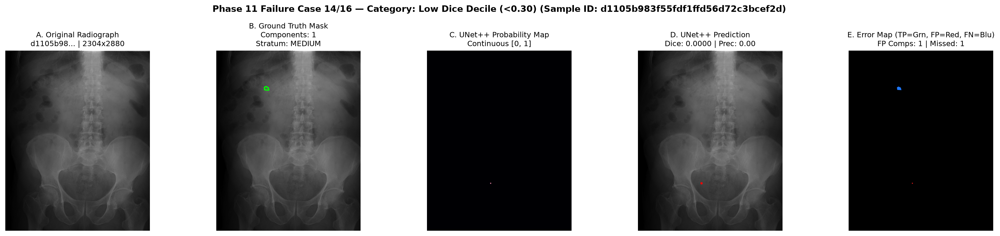

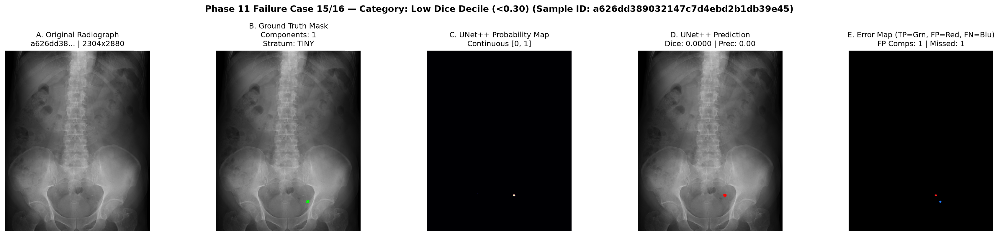

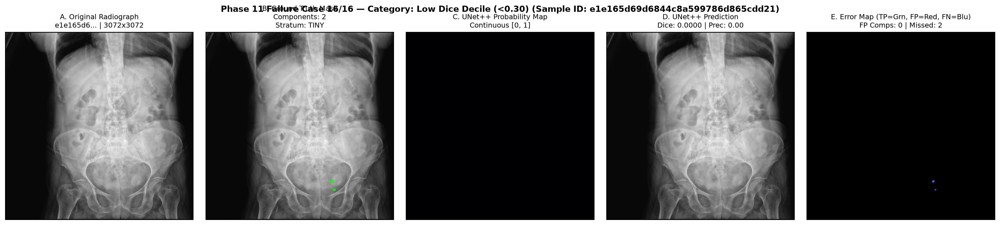

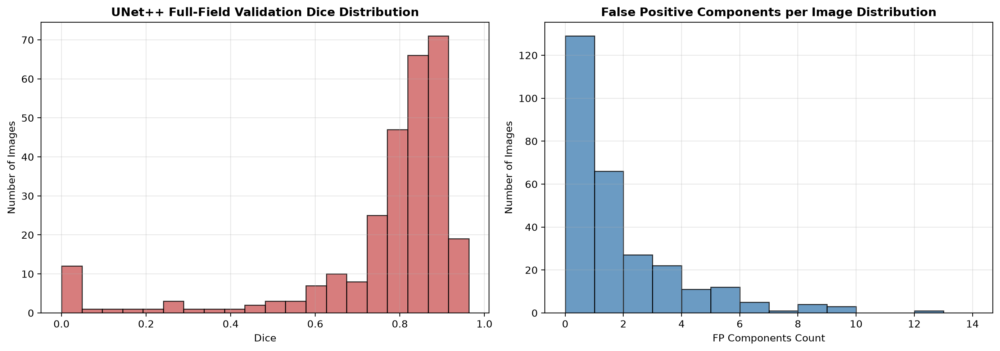

In [4]:
import glob
fig_pattern = 'reports/figures/retrospective/phase11_failures/failure_*.png' if os.path.exists('reports') else '../../reports/figures/retrospective/phase11_failures/failure_*.png'
fail_figs = sorted(glob.glob(fig_pattern))
for p in fail_figs[8:]:
    display(Image(filename=p))


## Section C: Scientific Interpretation & Why Phase 12 Was Needed
The failure cases conclusively demonstrate that:
1. **Global Resolution Bottleneck:** Subsampling full radiographs down to 512x512 removes distinguishing radio-opaque edges of tiny stones, causing the network output probability to remain near zero across true targets.
2. **False Positives:** Non-target radio-opacities (pelvic phleboliths, rib margins) lack context when downsampled, generating high false positive rates.

This established the imperative for **Phase 12 (Oracle ROI Study)** to test whether presenting high-resolution local crops can fundamentally resolve small stone targets.
